In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
## **DATA ANALYSIS PYTHON PROJECT - BLINKIT ANALYSIS**

In [3]:
df=pd.read_excel('BlinkIT Grocery Data.xlsx')
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [7]:
df.shape

(8523, 12)

In [8]:
df.dtypes

,0
Item Fat Content,object
Item Identifier,object
Item Type,object
Outlet Establishment Year,int64
Outlet Identifier,object
Outlet Location Type,object
Outlet Size,object
Outlet Type,object
Item Visibility,float64
Item Weight,float64


In [10]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat' 'LF' 'reg']


In [11]:
df['Item Fat Content']=df['Item Fat Content'].replace('LF','Low Fat')
df['Item Fat Content']=df['Item Fat Content'].replace('low fat','Low Fat')
df['Item Fat Content']=df['Item Fat Content'].replace('reg','Regular')

In [12]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat']


In [19]:
Total_Sales=df['Sales'].sum()
Avg_Sales=df['Sales'].mean()
No_Of_Items_Sold=df['Sales'].count()
Avg_Ratings=df['Rating'].mean()

print(f"Total_Sales: ${Total_Sales:,.0f}")
print(f"Avg_Sales: ${Avg_Sales:,.0f}")
print(f"No_Of_Items_Sold: ${No_Of_Items_Sold:,.0f}")
print(f"Avg_Ratings: ${Avg_Ratings:,.0f}")

Total_Sales: $1,201,681
Avg_Sales: $141
No_Of_Items_Sold: $8,523
Avg_Ratings: $4


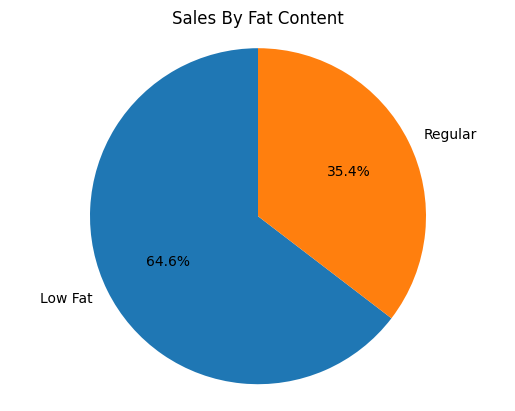

In [20]:
# TOTAL SALES BY FAT CONTENT
Sales_By_Fat=df.groupby('Item Fat Content')['Sales'].sum()
plt.pie(Sales_By_Fat,labels=Sales_By_Fat.index,autopct='%.1f%%',startangle=90)
plt.title('Sales By Fat Content')
plt.axis('equal')
plt.show()

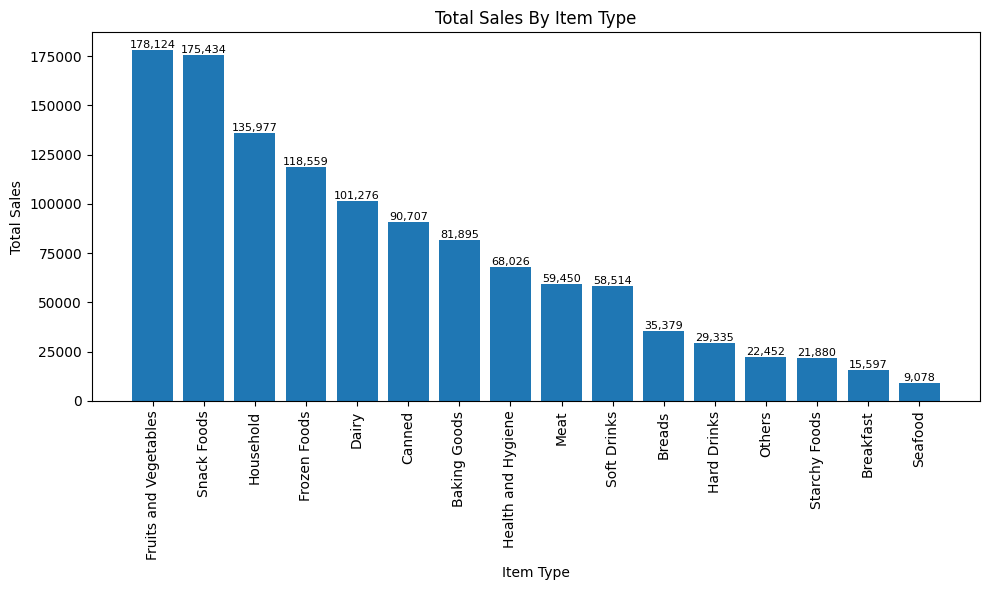

In [27]:
# TOTAL SALES BY ITEM TYPE
Sales_By_Item_Type=df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,6))
bars=plt.bar(Sales_By_Item_Type.index,Sales_By_Item_Type.values)

plt.xticks(rotation=90)
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.title('Total Sales By Item Type')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,bar.get_height(),f'{bar.get_height():,.0f}',ha='center',va='bottom',fontsize=8)
plt.tight_layout()
plt.show()

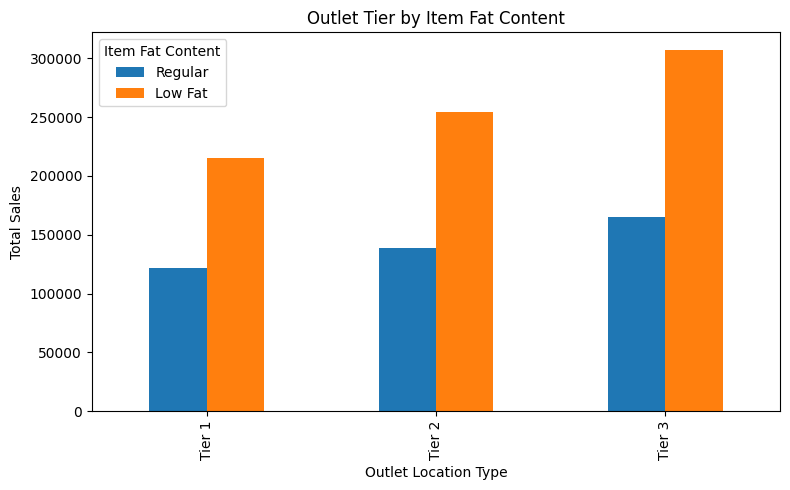

In [29]:
# FAT CONTENT BY OUTLET FOR TOTAL SALES
grouped=df.groupby(['Outlet Location Type','Item Fat Content'])['Sales'].sum().unstack()
grouped=grouped[['Regular','Low Fat']]

ax=grouped.plot(kind='bar',figsize=(8,5),title='Outlet Tier by Item Fat Content')
plt.xlabel('Outlet Location Type')
plt.ylabel('Total Sales')
plt.legend(title='Item Fat Content')
plt.tight_layout()
plt.show()


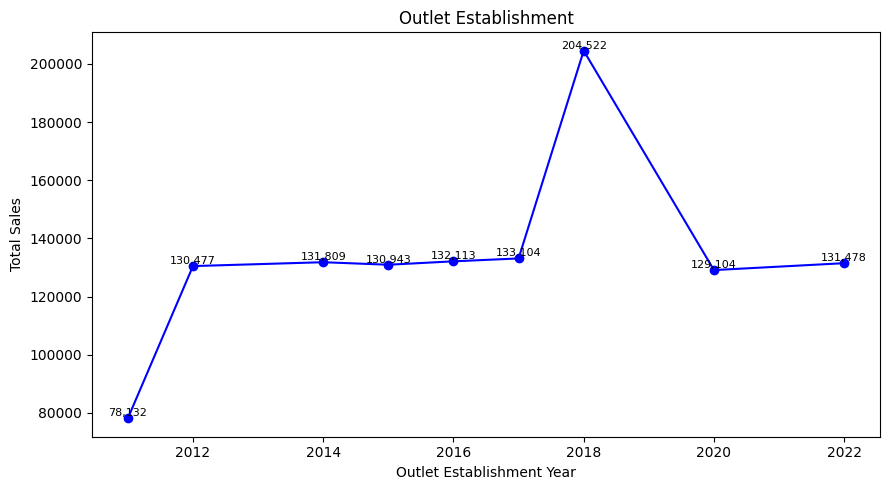

In [30]:
# TOTAL SALES BY OUTLET ESTABLISHMENT
sales_by_year=df.groupby('Outlet Establishment Year')['Sales'].sum().sort_index()
plt.figure(figsize=(9,5))
plt.plot(sales_by_year.index,sales_by_year.values,marker='o',linestyle='-',color='b')

plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.title('Outlet Establishment')

for x,y in zip(sales_by_year.index,sales_by_year.values):
    plt.text(x,y,f'{y:,.0f}',ha='center',va='bottom',fontsize=8)
plt.tight_layout()
plt.show()



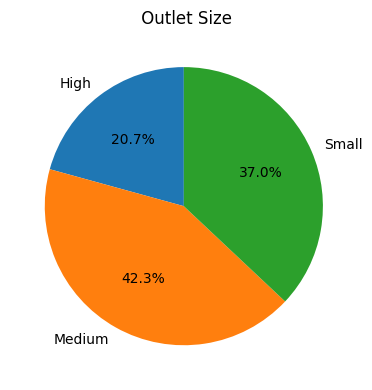

In [31]:
# SALES BY OUTLT SIZE
sales_by_size=df.groupby('Outlet Size')['Sales'].sum()

plt.figure(figsize=(4,4))
plt.pie(sales_by_size,labels=sales_by_size.index,autopct='%.1f%%',startangle=90)
plt.title(' Outlet Size')
plt.tight_layout()
plt.show()


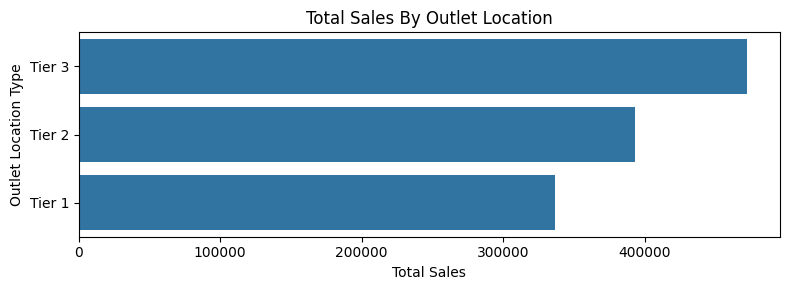

In [32]:
# SALES BY OUTLET LOCATION
sales_by_location=df.groupby('Outlet Location Type')['Sales'].sum().reset_index()
sales_by_location=sales_by_location.sort_values('Sales',ascending=False)

plt.figure(figsize=(8,3))
ax=sns.barplot(y='Outlet Location Type',x='Sales',data=sales_by_location)
plt.ylabel('Outlet Location Type')
plt.xlabel('Total Sales')
plt.title('Total Sales By Outlet Location')

plt.tight_layout()
plt.show()